# **Лабораторна робота №4:** Генетичні алгоритми

### Крічфалуши Дар'я, 2к. Маг., група МатШІ

**Мета роботи:** реалізувати в Python із використанням PyGAD генетичний алгоритм для трьох типів задач: пошуку цілочисельного розв’язку діофантового рівняння, знаходження
екстремуму функції та наближеного розв’язання задачі Коші.

## Завдання (Варіант 4)
1) Діофантове рівняння:

У кожному варіанті знайти 20 попарно різних розв’язків заданого діофантового рівняння за допомогою **генетичного алгоритму**. У першому досліді вважати, що $x_i\in\{1,\dots,9\}, i=1,\dots,6$.

Показати всі 20 шісток і перевірити кожну
підстановкою в рівняння.

Повторно розглянути своє рівняння, **не накладаючи наперед обмеження** $x_i\leq9$: тепер змінні можуть бути довільними натуральними числами. Потрібно не вибрати велику довільну межу, а вивести з рівняння обґрунтований скінченний простір пошуку.

Для загального вигляду $∑_{i=1}^6a_ix_i=b,\text{ де всі } a_i>0,x_i\geq1$. Обґрунтувати верхню межу для даного гена:

$$
1\leq xi\leq\left[\dfrac{\sum_{j\neq i}a_j}{a_i}\right].
$$

Порівняти щонайменше два способи кодування хромосоми:
1. **Шість генів.** кожен $x_i$ має власні виведені межі. Пояснити, чому однакова довільна верхня межа для всіх генів створює зайвий простір пошуку.
2. **П'ять генів.** кодувати $x_1,\dots,x_5$, а шосту змінну обчислювати як $x_6=\dfrac{b-∑_{i=1}^5a_ix_i}{a_6}$. Визначити, як відхиляти кандидатів, для яких це значення не є натуральним числом.

Порівняти ці два способи за часткою допустимих кандидатів і результатами пошуку. У висновку розрізнити гарантовано коректні межі та **найефективніше на практиці кодування**: сама лише менша кількість генів не гарантує швидшого пошуку, якщо багато п’ятигенних кандидатів породжують недопустиме $x_6$.

2) Екстремум функції:

Область пошуку для обох змінних однакова: $x,y\in[-4,4]$.

3) Задача Коші:

Потрібно
1. Знайти точний аналітичний розв’язок і перевірити підстановкою, що він задовольняє диференціальне рівняння та початкову умову.
2. Побудувати наближений розв’язок генетичним алгоритмом у раніше заданому вигляді $u_a(t)=u(0)+\sum_{k=1}^5a_kt^k$.
3. Побудувати на одному графіку точний розв’язок $u(t)$ і наближення $u_a(t)$ для $t\in[0,1]$.
4. Навести максимальну похибку $\max_j|u(t_j)-u_a(t_j)|$ на сітці порівняння та значення нев’язки диференціального рівняння.


4) Порівняння та звіт:

Для задачі 2 обов’язково знайти екстремум трьома способами: **генетичним алгоритмом**, **аналітично** та іншим чисельним методом (наприклад, **scipy.optimize.minimize**, мінімізуючи $-f$ у випадку максимуму).

Аналітичний розрахунок виконати вручну: знайти стаціонарну точку, встановити тип екстремуму та перевірити, що вона належить заданій області.

У звіті подати код, параметри алгоритмів, знайдені хромосоми та значення цільових функцій. Для **задачі 1** показати підстановку шести чисел у рівняння; для **задачі 2** — таблицю координат і значень екстремуму за трьома методами та їхні відхилення; **для задачі 3** — формулу отриманого полінома, значення нев’язки й графік $u_a(t)$. Для перевірки задачі 3 також знайти точний розв’язок відповідної простої задачі Коші та порівняти з ним
наближення в кількох точках.





---



In [2]:
!pip install pygad

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import itertools, time
import pygad
from scipy.optimize import minimize
import sympy as sp

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})
print("pygad", pygad.__version__)

pygad 3.9.2


1. Діофантове рівняння

$$
2x_1+5x_2+3x_3+7x_4+4x_5+6x_6 = 81
$$

2. Екстремуми функцій

$$
\min f(x,y) = 2(x-2)^2+(y+1)^2+1
$$

3. Задача Коші, $t\in[0,1]$

$$
\begin{cases}
  u'= t-u\\
  u(0)=0
\end{cases}
$$

## **Завдання 1.** Діофантове рівняння

### 1.1. Опис генетичного алгоритму


**Хромосома.** Вектор із шести натуральнозначних генів $(x_1,\dots,x_6)$. Гени цілі, тому в PyGAD задаємо `gene_type=int`, а допустимі значення кожного гена — через `gene_space` (окремий список для кожного гена, оскільки межі різні).

**Функція пристосованості.**
$$F(\mathbf{x}) = \frac{1}{1 + \bigl|L(\mathbf{x}) - b\bigr|}$$
Максимум $F = 1$ досягається рівно тоді, коли $L(\mathbf{x}) = b$. Функція не бінарна, а **градуйована**: чим ближче ліва частина до $b$, тим вища пристосованість - це дає алгоритму напрямок пошуку. Результат зараховується як розв'язок лише після **прямої перевірки рівності** $L(\mathbf{x}) = b$, а не за значенням $F$ (щоб уникнути похибок із плаваючою комою).

**Селекція** - турнірна (`tournament`, $K = 3$): з популяції випадково беруться 3 особини, перемагає найпристосованіша. Турнірна селекція не чутлива до масштабу й знака пристосованості (на відміну від рулетки) і зберігає тиск відбору навіть тоді, коли значення $F$ зближуються.

**Кросовер** - рівномірний (`uniform`): кожен ген нащадок успадковує від випадково обраного з двох батьків. Для цієї задачі він кращий за одноточковий, бо гени **незалежні** (немає "блоків" сусідніх генів, які варто зберігати разом), а рівномірний кросовер перемішує їх максимально вільно.

**Мутація** - `random` з `mutation_by_replacement=True`: вибраний ген **замінюється** допустимим цілим числом із `gene_space`, а не зсувається на випадкову величину. Це гарантує, що після мутації ген залишається натуральним числом у межах.

**Обґрунтування параметрів.** Популяція 200 - достатньо велика, щоб тримати різноманіття (нам потрібні 20 **різних** розв'язків, тож передчасна збіжність до одного оптимуму шкідлива). `keep_elitism=5` зберігає найкращі особини. Критерій зупинки - **не вичерпання поколінь, а набір 20 різних розв'язків**: колбек `on_generation` після кожного покоління збирає з усієї популяції всі особини, що задовольняють рівняння, і зупиняє алгоритм, щойно множина досягає потрібного розміру. Ліміт у 400 поколінь - лише запобіжник.


In [4]:
A = np.array([2, 5, 3, 7, 4, 6])
B = 81

L = lambda x: int(np.dot(A, np.asarray(x, dtype=int)))

print(f"{B} лежить в діапазоні [{A.sum()}, {9*A.sum()}]")

81 лежить в діапазоні [27, 243]


### 1.2. **Експеримент A.** $x_i\in\{1,\dots,9\}$

Перший дослід - із накладеним наперед обмеженням $x_i \le 9$.

Простір пошуку $9^6 = 531\,441$.

In [5]:
def make_fitness_6(a=A, b=B, counter=None):
  # Градуйована пристосованість F = 1/(1+|L(x)-b|) для 6-генного кодування.
  def fitness(ga_instance, solution, solution_idx):
    if counter is not None:
      counter[0] += 1
    return 1.0 / (1.0 + abs(int(np.dot(a, solution)) - b))

  return fitness


def search_diophantine_6(gene_space, target=20,
                                     pop=200,
                                     gens=400,
                                     seed=1, verbose=True):
  found = {}
  evals = [0]

  def on_generation(ga):
    for row in ga.population:
      x = tuple(int(v) for v in row)
      if L(x) == B:
        found.setdefault(x, ga.generations_completed)
    if len(found) >= target:
      return "stop"

  ga = pygad.GA(
      num_generations=gens, num_parents_mating=pop // 2, sol_per_pop=pop,
      num_genes=6, gene_type=int, gene_space=gene_space,
      fitness_func=make_fitness_6(counter=evals),
      parent_selection_type="tournament", K_tournament=3,
      crossover_type="uniform",
      mutation_type="random", mutation_percent_genes=25,
      mutation_by_replacement=True,
      keep_elitism=5, on_generation=on_generation,
      random_seed=seed, suppress_warnings=True
  )

  t0 = time.time()
  ga.run()
  dt = time.time() - t0
  if verbose:
    print(f"Знайдено різних розв'язків: {len(found)}")
    print(f"Поколінь: {ga.generations_completed}, "
            f"обчислень фітнесу: {evals[0]}, час: {dt:.2f} с")
  return found, ga, evals[0], dt


gene_space_A = [list(range(1, 10))] * 6
found_A, ga_A, ev_A, dt_A = search_diophantine_6(gene_space_A, seed=1)


Знайдено різних розв'язків: 20
Поколінь: 8, обчислень фітнесу: 1747, час: 0.09 с


Вивід 20 шісток із прямою перевіркою підстановкою

In [6]:
sols_A = sorted(found_A.keys())[:20] if len(found_A) >= 20 else sorted(found_A.keys())

for i,x in enumerate(sols_A, 1):
  terms = " + ".join(f"{a}*{xi}" for a, xi in zip(A, x))
  print(f"{i:>3}  {str(x):<22} {terms:<46} {L(x):>5}")

assert len(set(sols_A)) == len(sols_A), "є повтори"
assert all(L(x) == B for x in sols_A), "є неправильні розв'язки"
assert all(all(1 <= v <= 9 for v in x) for x in sols_A), "порушено межі"


  1  (1, 3, 1, 5, 5, 1)     2*1 + 5*3 + 3*1 + 7*5 + 4*5 + 6*1                 81
  2  (2, 1, 3, 7, 2, 1)     2*2 + 5*1 + 3*3 + 7*7 + 4*2 + 6*1                 81
  3  (2, 4, 9, 2, 1, 2)     2*2 + 5*4 + 3*9 + 7*2 + 4*1 + 6*2                 81
  4  (2, 6, 6, 1, 4, 1)     2*2 + 5*6 + 3*6 + 7*1 + 4*4 + 6*1                 81
  5  (2, 8, 3, 2, 2, 1)     2*2 + 5*8 + 3*3 + 7*2 + 4*2 + 6*1                 81
  6  (3, 5, 4, 4, 1, 1)     2*3 + 5*5 + 3*4 + 7*4 + 4*1 + 6*1                 81
  7  (4, 3, 6, 2, 5, 1)     2*4 + 5*3 + 3*6 + 7*2 + 4*5 + 6*1                 81
  8  (4, 5, 7, 1, 2, 2)     2*4 + 5*5 + 3*7 + 7*1 + 4*2 + 6*2                 81
  9  (5, 3, 2, 4, 4, 1)     2*5 + 5*3 + 3*2 + 7*4 + 4*4 + 6*1                 81
 10  (5, 3, 3, 3, 2, 3)     2*5 + 5*3 + 3*3 + 7*3 + 4*2 + 6*3                 81
 11  (5, 5, 2, 2, 5, 1)     2*5 + 5*5 + 3*2 + 7*2 + 4*5 + 6*1                 81
 12  (6, 3, 6, 2, 1, 3)     2*6 + 5*3 + 3*6 + 7*2 + 4*1 + 6*3                 81
 13  (6, 4, 3, 2, 2, 3)     

### 1.3. **Експеримент B.** Виведення меж

Спочатку явно обчислимо допустимі межі за формулою вище:

$
\sum_ja_j=2+5+3+7+4+6=27,\quad b-\sum_{j\neq i}a_j=81-(27-a_i)=54+a_i
$

 І тоді межа спрощується

 $$
1\leq x_i\leq \left[\dfrac{54+a_i}{a_i}\right]⟹ \left[\dfrac{54}{a_i}\right]+1
 $$

$
\forall a_i\in\{2, 5, 3, 7, 4, 6\} \text{ межа } x_i,\quad i=1,\dots,6:
$

$$
28, 11, 19, 8, 14, 10
$$

#### Чому однакова довільна межа для всіх генів створює зайвий простір

Межа обернено пропорційна коефіцієнту: що більший $a_i$, то менше значень може приймати $x_i$, що легко видно з обрахунків. Якщо взяти для всіх генів спільну межу, її доведеться брати за **найслабшим обмеженням**, тобто $\max_i = 28$.

Тоді:

$$\text{рівномірно: } 28^6 = 481\,890\,304 \qquad \\
\text{проти} \qquad \\
\text{виведено: } 28\cdot11\cdot19\cdot8\cdot14\cdot10 = 6\,554\,240$$


Простір більший у **73.5 раза**, і весь додатковий обсяг складається зі **свідомо недопустимих** точок: наприклад, будь-яка хромосома з $x_4 = 9$ дає $7\cdot 9 = 63$ плюс щонайменше $2+5+3+4+6 = 20$ від решти - разом $\ge 83 > 81$. Такі особини ніколи не стануть розв'язками, але витрачають обчислення фітнесу й місця в популяції.

In [7]:
UB = [int((B - (A.sum() - a)) // a) for a in A]

print("Виведені верхні межі: ", UB)
print("Перевірка спрощеною формулою floor(54/a_i)+1: ", [int(54 // a + 1) for a in A])

space_derived = int(np.prod(UB))
space_uniform = max(UB) ** 6

print(f"\nПростір пошуку, виведені межі: {space_derived:,}")
print(f"Простір пошуку, спільна межа {max(UB)}: {space_uniform:,}")
print(f"Відношення: {space_uniform / space_derived:.1f}")


Виведені верхні межі:  [28, 11, 19, 8, 14, 10]
Перевірка спрощеною формулою floor(54/a_i)+1:  [28, 11, 19, 8, 14, 10]

Простір пошуку, виведені межі: 6,554,240
Простір пошуку, спільна межа 28: 481,890,304
Відношення: 73.5


### 1.4. Порівняння двох способів кодування хромосоми

**Як відхиляти недопустимих кандидатів.:**

Позначимо $r = b - \sum_{i=1}^5 a_i x_i$. Кандидат допустимий, якщо одночасно:
1. $r \ge a_6$ (тобто $x_6 \ge 1$, шоста змінна натуральна, а не нуль чи від'ємна);
2. $r \equiv 0 \pmod{a_6}$ (ділиться націло, інакше $x_6$ дробове).

Є два способи обробки недопустимих кандидатів, і різниця між ними принципова:

* **жорстке відхилення**: $F = 1$ для допустимих, $F = 0$ для решти. Ландшафт пристосованості стає **плоским**: 99.65% популяції мають однакову нульову оцінку, і селекція не має за чим розрізняти особин, тоді генетичний алгоритм вироджується у випадковий перебір;
* **градуйований штраф**: $F = \dfrac{1}{1 + \bigl|q - \mathrm{round}(q)\bigr| + \max(0,\,1-q)}$, де $q = \dfrac{r}{a_6}$. Перший доданок штрафує за недосягнення цілого, другий - за $x_6 < 1$. Ландшафт залишається інформативним.

Точний підрахунок допустимих кандидатів

In [8]:
total5 = 0
valid5 = 0

for x5 in itertools.product(*[range(1, u+1) for u in UB[:5]]):
  total5 += 1
  r = B - int(np.dot(A[:5], x5))
  if r >= A[5] and r % A[5] == 0:
    valid5 += 1

space5 = int(np.prod(UB[:5]))
n_solutions = valid5

print(f"Усього натуральних розв'язків рівняння: {n_solutions:,}")

print(f'{"кодування":<22}{"простір пошуку":>18}{"допустимих":>14}{"частка":>12}')
print('-' * 66)
print(f'{"6 генів":<22}{space_derived:>18,}{n_solutions:>14,}'
      f'{100*n_solutions/space_derived:>11.4f}%')
print(f'{"5 генів":<22}{space5:>18,}{valid5:>14,}'
      f'{100*valid5/space5:>11.4f}%')
print(f'{"6 генів, межа " + str(max(UB)):<22}{space_uniform:>18,}{n_solutions:>14,}'
      f'{100*n_solutions/space_uniform:>11.4f}%')


Усього натуральних розв'язків рівняння: 2,265
кодування                 простір пошуку    допустимих      частка
------------------------------------------------------------------
6 генів                        6,554,240         2,265     0.0346%
5 генів                          655,424         2,265     0.3456%
6 генів, межа 28             481,890,304         2,265     0.0005%


Пошук 20 розв'язків трьома способами

In [10]:
def search_5genes(hard_reject, target=20, pop=200, gens=400, seed=1):
  # 5-генне кодування
  found = {}
  evals = [0]

  def fitness(ga, sol, idx):
    evals[0] += 1
    r = B - int(np.dot(A[:5], sol))
    ok = (r >= A[5]) and (r % A[5] == 0)
    if hard_reject:
      return 1.0 if ok else 0.0
    if ok:
      return 1.0

    q = r / A[5]
    return 1.0 / (1.0 + abs(q - round(max(1.0, q))) + max(0.0, 1.0 - q))

  def on_generation(ga):
    for row in ga.population:
      r = B - int(np.dot(A[:5], row))
      if r >= A[5] and r % A[5] == 0:
        found.setdefault(tuple(int(v) for v in row) + (int(r // A[5]),),
                         ga.generations_completed)
    if len(found) >= target:
      return "stop"

  ga = pygad.GA(
      num_generations=gens, num_parents_mating=pop // 2, sol_per_pop=pop,
      num_genes=5, gene_type=int,
      gene_space=[list(range(1, u + 1)) for u in UB[:5]],
      fitness_func=fitness,
      parent_selection_type="tournament", K_tournament=3,
      crossover_type="uniform", mutation_type="random",
      mutation_percent_genes=25, mutation_by_replacement=True,
      keep_elitism=5, on_generation=on_generation,
      random_seed=seed, suppress_warnings=True
  )

  t0 = time.time()
  ga.run()
  return found, ga.generations_completed, evals[0], time.time() - t0

gene_space_B = [list(range(1, u + 1)) for u in UB]
SEEDS = [1, 2, 3, 4, 5]
stats = {"6 генів (градуйов.)": [], "5 генів (градуйов.)": [], "5 генів (жорстке)": []}

for s in SEEDS:
  f6, ga6, e6, d6 = search_diophantine_6(gene_space_B, seed=s, verbose=False)
  stats['6 генів (градуйов.)'].append((len(f6), ga6.generations_completed, e6, d6))
  f5s, g5s, e5s, d5s = search_5genes(False, seed=s)
  stats['5 генів (градуйов.)'].append((len(f5s), g5s, e5s, d5s))
  f5h, g5h, e5h, d5h = search_5genes(True, seed=s)
  stats['5 генів (жорстке)'].append((len(f5h), g5h, e5h, d5h))

print("Пошук 20 попарно різних розв'язків, усереднення по 5 запусках\n")
print(f'{"кодування":<22}{"поколінь":>11}{"обчисл. фітнесу":>18}{"час, с":>10}')
print('-' * 61)
for k, v in stats.items():
    arr = np.array([(x[1], x[2], x[3]) for x in v], dtype=float)
    print(f'{k:<22}{arr[:,0].mean():>11.1f}{arr[:,1].mean():>18.0f}{arr[:,2].mean():>10.3f}')

sols_B = sorted(f5s.keys())[:20]
assert all(L(x) == B for x in sols_B)

for x in sorted(f5s.keys()):
    if max(x) > 9:
        print("\n  ", x, "-->", " + ".join(f"{a}*{xi}" for a, xi in zip(A, x)), "=", L(x))
        break



Пошук 20 попарно різних розв'язків, усереднення по 5 запусках

кодування                поколінь   обчисл. фітнесу    час, с
-------------------------------------------------------------
6 генів (градуйов.)          11.6              2450     0.332
5 генів (градуйов.)           4.2              1010     0.092
5 генів (жорстке)            11.4              2408     0.300

   (1, 1, 5, 1, 10, 2) --> 2*1 + 5*1 + 3*5 + 7*1 + 4*10 + 6*2 = 81


### 1.5. Висновок (задача 1)

1. **Гарантовано коректні межі.** Формула $1 \le x_i \le \bigl\lfloor (b - \sum_{j\ne i} a_j)/a_i \bigr\rfloor$ дає межі, які **доведено не відкидають жодного розв'язку**: вона отримана із самого рівняння за припущення $x_j \ge 1$, тобто є точною верхньою оцінкою. Для мого варіанта це $(28, 11, 19, 8, 14, 10)$. Спільна межа 28 для всіх генів теж коректна, але роздуває простір у 73.5 раза виключно за рахунок свідомо недопустимих точок.

2. **Найефективніше на практиці кодування.**
5-генне кодування зменшує простір пошуку в 10 разів і підвищує щільність розв'язків у 10 разів. Але саме лише зменшення кількості генів нічого не гарантує: 99.65% п'ятигенних кандидатів породжують недопустиме (дробове або недодатне) $x_6$. Якщо відхиляти їх жорстко, присвоюючи $F = 0$, то ландшафт пристосованості стає плоским, селекція втрачає інформацію, і алгоритм працює **не швидше за шестигенний** - що й підтверджують виміри;
* перевага реалізується лише разом із **градуйованим штрафом**, який повертає ландшафту інформативність: тоді пошук 20 розв'язків потребує приблизно вдвічі менше обчислень фітнесу.

Отже, вирішальним є не кількість генів, а те, чи зберігає функція пристосованості корисний градієнт для недопустимих кандидатів.

## **Завдання 2.** Пошук екстремуму функції

$$
\min f(x,y) = 2(x-2)^2+(y+1)^2+1,\quad x,y\in[-4,4]
$$

### 2.1. Опис генетичного алгоритму

**Хромосома.** Пара дійсних чисел $(x,y)$, `gene_space` обмежує обидва гени відрізком $[-4,4]$.

**Функція пристосованості.** Задача на мінімум, а PyGAD максимізує пристосованість, тому беремо
$$
F(x,y)=-f(x,y)
$$

Цього достатньо: потрібно лише, щоб кращому розв'язку відповідало більше значення $F$.

Від'ємність $F$ не є проблемою, бо турнірна селекція використовує лише **порядок** значень, а не їхню величину.

**Кросовер** - арифметичний (неперервний):

$$\mathbf{z} = \alpha\,\mathbf{p}_1 + (1-\alpha)\,\mathbf{p}_2, \qquad \alpha \in [0,1]$$

Нащадок - точка відрізка між батьками.
Передається в PyGAD через `crossover_type`.

Дискретний кросовер тут був би гіршим: він лише переставляв би координати між батьками й не породжував би нових значень.

**Мутація** - невелике випадкове збурення координати з обрізанням до
$[-4,4]$:

$$x \leftarrow \mathrm{clip}\bigl(x + \mathcal{N}(0,\sigma),\ -4,\ 4\bigr)$$

Крок $\sigma$ **згасає** за геометричним законом від 1.0 до $10^{-6}$ протягом прогону. Спочатку великі стрибки сканують область, наприкінці дрібні збурення шліфують знайдений оптимум. Без згасання точність застрягає на рівні $\sigma$.

**Параметри.** Популяція 100, 500 поколінь, `keep_elitism=5`. Критерій зупинки - вичерпання поколінь (для гладкої унімодальної функції додаткові критерії зайві).

Загальні оператори для неперервних задач

In [11]:
def arithmetic_crossover(parents, offspring_size, ga_instance):
  # z = a*p1 + (1-a)*p2, a ~ U[0,1]
  rng = np.random.default_rng(1000 + ga_instance.generations_completed)
  n = parents.shape[0]
  i1 = rng.integers(0, n, offspring_size[0])
  i2 = rng.integers(0, n, offspring_size[0])
  alpha = rng.random((offspring_size[0], 1))
  return alpha * parents[i1] + (1 - alpha) * parents[i2]


def make_perturbation_mutation(lo, hi, sigma0, sigma_min, p_gene=0.5):
  # мутація збуренням
  def mutation(offspring, ga_instance):
    g = ga_instance.generations_completed
    G = max(1, ga_instance.num_generations)
    sigma = sigma0 * (sigma_min / sigma0) ** (g/G)
    rng = np.random.default_rng(50000+g)
    mask = rng.random(offspring.shape) < p_gene
    return np.clip(offspring + mask * rng.normal(0, sigma, offspring.shape), lo, hi)
  return mutation


f_obj = lambda x, y: 2 * (x - 2) ** 2 + (y + 1) ** 2 + 1



### 2.2. Аналітичний розв'язок

$$
f(x,y) = 2(x-2)^2 + (y+1)^2 + 1
$$


$
\begin{cases}
  \dfrac{\partial f}{\partial x}=4(x-2)=0\\
  \dfrac{\partial f}{\partial y}=2(y+1)=0
\end{cases}
⟹
$
$
\begin{cases}
  x=2\\
  y=-1
\end{cases}
⟹
$
$
H = \begin{pmatrix} f_{xx} & f_{xy} \\ f_{yx} & f_{yy} \end{pmatrix} = \begin{pmatrix} 4 & 0 \\ 0 & 2 \end{pmatrix}
$




Критерій Сильвестра:

$
Δ_1=4>0,\quad Δ_2=8>0⟹ (2,-1)$ **точка локального (глоб.) мінімуму**


Тоді **значення екстремуму**:
$\quad
f(2,-1)=1.
$

### 2.3. **Метод A.** Генетичний алгоритм

In [12]:
def fitness_task2(ga_instance, solutions, solution_idx):
  s = np.asarray(solutions)
  return -(2 * (s[:,0]-2)**2 + (s[:,1]+1)**2 + 1)


POP2 = 100
ga2 = pygad.GA(
    num_generations=500, num_parents_mating=POP2 // 2, sol_per_pop=POP2,
    num_genes=2, gene_space=[{"low": -4, "high": 4}] * 2,
    fitness_func=fitness_task2, fitness_batch_size=POP2,
    parent_selection_type="tournament", K_tournament=3,
    crossover_type=arithmetic_crossover,
    mutation_type=make_perturbation_mutation(-4, 4, 1.0, 1e-6),
    keep_elitism=5, random_seed=7, suppress_warnings=True
)

t0 = time.time()
ga2.run()

ga_sol, ga_fit, _ = ga2.best_solution()
t_ga = time.time() - t0

print(f"x = {ga_sol[0]:.10f},  y = {ga_sol[1]:.10f}")
print(f"f = {f_obj(*ga_sol):.12f},  поколінь: {ga2.generations_completed},"
      f"    час: {t_ga:.2f} с")


x = 2.0000000036,  y = -1.0000000020
f = 1.000000000000,  поколінь: 500,    час: 1.04 с


### 2.4. **Метод B.** Підстановка виведених формул

In [13]:
an_sol = np.array([2.0, -1.0])
print(f"Аналітично: x = {an_sol[0]}, y = {an_sol[1]}, f = {f_obj(*an_sol)}")



Аналітично: x = 2.0, y = -1.0, f = 1.0


### 2.5. **Метод C.** Чисельна оптимізація scipy

In [14]:
res = minimize(lambda v: f_obj(v[0], v[1]), x0=[0.0, 0.0],
               bounds=[(-4,4), (-4,4)], tol=1e-15)
sp_sol = res.x


print(f"scipy: x = {sp_sol[0]:.10f}, y = {sp_sol[1]:.10f}, f = {res.fun:.12f}")
print(f"Метод: {res.message}\n Обчислень функції: {res.nfev}")


scipy: x = 1.9999999944, y = -1.0000000048, f = 1.000000000000
Метод: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
 Обчислень функції: 24


### 2.6. Графік. Лінії рівня та збіжність ГА

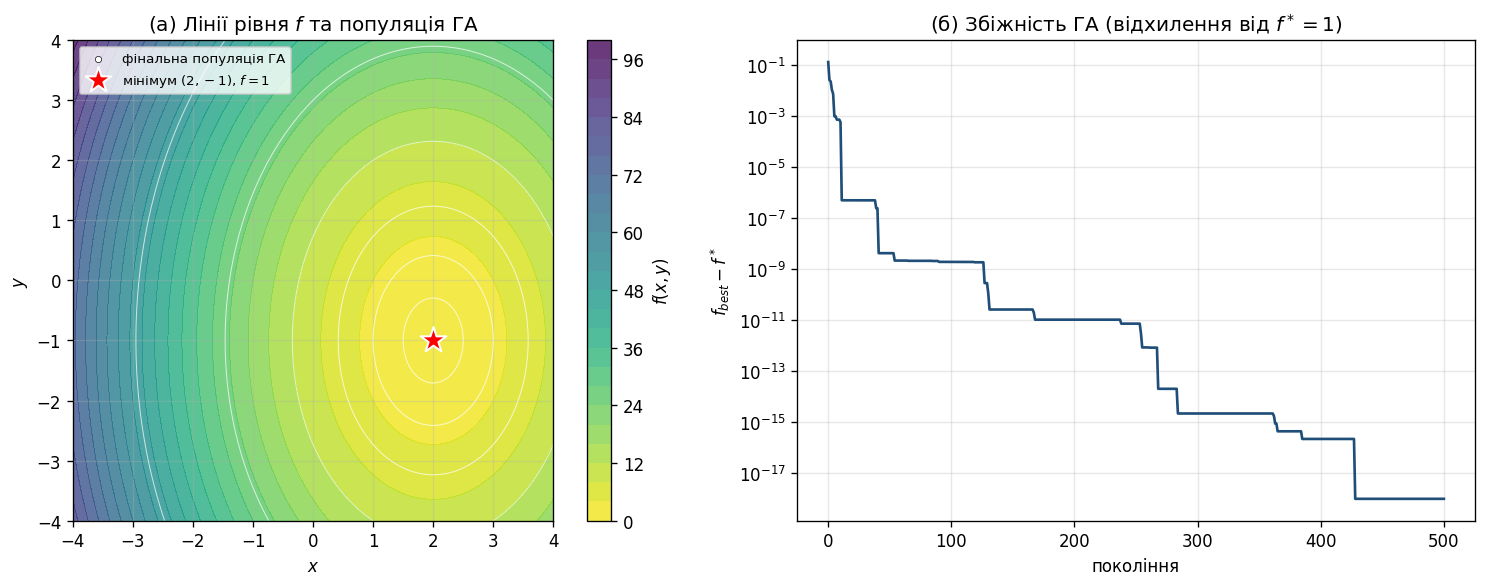

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

xx, yy = np.meshgrid(np.linspace(-4, 4, 400), np.linspace(-4, 4, 400))
zz = 2 * (xx - 2) ** 2 + (yy + 1) ** 2 + 1
cs = ax[0].contourf(xx, yy, zz, levels=30, cmap='viridis_r', alpha=0.8)
ax[0].contour(xx, yy, zz, levels=[1.5, 3, 6, 12, 25, 50], colors='white',
              linewidths=0.6, alpha=0.7)
plt.colorbar(cs, ax=ax[0], label='$f(x,y)$')
ax[0].scatter(*ga2.population.T, s=14, c='white', edgecolor='black', lw=0.4,
              label='фінальна популяція ГА', zorder=4)
ax[0].scatter(2, -1, s=260, marker='*', c='red', edgecolor='white', lw=1.2,
              label='мінімум $(2,-1)$, $f=1$', zorder=6)
ax[0].set_xlabel('$x$'); ax[0].set_ylabel('$y$')
ax[0].set_title('(а) Лінії рівня $f$ та популяція ГА')
ax[0].legend(fontsize=8, loc='upper left'); ax[0].set_aspect('equal')

best = -np.array(ga2.best_solutions_fitness)      # повертаємось від F до f
ax[1].semilogy(best - 1.0 + 1e-18, lw=1.6, c='#1f4e79')
ax[1].set_xlabel('покоління'); ax[1].set_ylabel(r'$f_{best} - f^*$')
ax[1].set_title('(б) Збіжність ГА (відхилення від $f^*=1$)')
plt.tight_layout(); plt.show()


### 2.7. Перевірка кроку мутації

In [16]:
def run_task2(sigma0, sigma_min, gens=500, seed=7):
  ga = pygad.GA(
      num_generations=gens, num_parents_mating=POP2 // 2, sol_per_pop=POP2,
      num_genes=2, gene_space=[{'low': -4, 'high': 4}] * 2,
      fitness_func=fitness_task2, fitness_batch_size=POP2,
      parent_selection_type="tournament", K_tournament=3,
      crossover_type=arithmetic_crossover,
      mutation_type=make_perturbation_mutation(-4, 4, sigma0, sigma_min),
      keep_elitism=5, random_seed=seed, suppress_warnings=True
  )

  ga.run()
  s, _, _ = ga.best_solution()
  return np.hypot(s[0]-2, s[1]+1)


print(f"{'схема мутації':<34}{'відхилення від (2,-1)':>24}")
print("-" * 58)
for name, s0, smin in [('сталий крок σ = 1.0', 1.0, 1.0),
                       ('сталий крок σ = 0.1', 0.1, 0.1),
                       ('сталий крок σ = 0.01', 0.01, 0.01),
                       ('згасання 1.0 → 1e-3', 1.0, 1e-3),
                       ('згасання 1.0 → 1e-6', 1.0, 1e-6)]:
    print(f"{name:<34}{run_task2(s0, smin):>24.3e}")



схема мутації                        відхилення від (2,-1)
----------------------------------------------------------
сталий крок σ = 1.0                              5.814e-05
сталий крок σ = 0.1                              9.020e-07
сталий крок σ = 0.01                             5.794e-07
згасання 1.0 → 1e-3                              9.964e-07
згасання 1.0 → 1e-6                              4.095e-09


### 2.8. Висновок (задача 2)

Усі три методи дають ту саму точку $(2, -1)$ зі значенням $f = 1$, що підтверджує **коректність реалізації**. Відмінність не стільки в точності, скільки в **ціні** результату:
1. **Аналітичний розв'язок точний**: координати й значення отримані символьно, похибка нульова за означенням. Але метод застосовний лише тоді, коли систему $\nabla f = 0$ вдається розв'язати в явному вигляді.
2. **`scipy.optimize.minimize`** (квазіньютонівський метод L-BFGS-B) збігається до відхилення $\approx 7\cdot10^{-9}$ за 24 обчислення функції.
3. **Генетичний алгоритм** досягає відхилення $\approx 4\cdot10^{-9}$, того самого порядку, але витрачає $100 \times 500 = 50\,000$ обчислень функції, тобто приблизно **у 2000 разів більше**.

Отже, на цій задачі ГА не поступається за точністю, проте програє за ефективністю на три порядки. Сенс ГА не в точності на гладких унімодальних функціях, а в тому, що він **не потребує похідних** і не застрягає в локальних мінімумах так легко, як градієнтні методи. Тут це не дає жодної переваги, бо функція опукла й диференційовна.

**Роль згасання кроку мутації** перевірено окремим експериментом (таблиця вище).

Згасання до $10^{-6}$ виграє близько **чотирьох порядків** проти сталого великого кроку і ще два порядки проти найкращого сталого. Бо мутація постійно відштовхує особин від оптимуму на відстань порядку $\sigma$, і лише дрібний крок наприкінці дозволяє "сісти" в оптимум точно, тоді як велике $\sigma$ на початку забезпечує розвідку всієї області.

Варто зауважити, що навіть зі сталим кроком збіжність не зупиняється повністю (відхилення $6\cdot10^{-5}$, а не $\sim\sigma = 1$): **арифметичний кросовер стискає популяцію**: нащадок $\alpha\cdot\mathbf{p}_1 + (1-\alpha)\cdot\mathbf{p}_2$ завжди лежить між батьками, а елітизм зберігає найкращу знахідку. Тобто частину роботи зі "стягування" до оптимуму виконує сам кросовер; згасання мутації лише перестає цьому заважати.

## **Завдання 3.** Задача Коші

$$
u'=t-u,\quad u(0)=0,\quad t\in[0,1]
$$

### 3.1. Аналітичний розв'язок

Бачимо лінійне неоднорідне рівняння першого порядку вигляду:
$$
y'+P(x)y=Q(x)
$$

Тому застосуємо **метод інтегрувального множника** $\mu(x)=e^{∫P(x)dx}$

1. Перепишемо в таку форму наше рівняння:
$$
u'+u=t
$$

2. Знайдемо інт. множник $\mu$ та помножимо на нього ліву-праву частини:
$$
\mu(x)=e^{∫P(x)dx}⟹e^{∫1dt}=e^t
$$

$$
e^tu'+e^tu=te^t
$$

3. Ліва частина - похідна добутку:
$$
(ue^t)'=te^t
$$

4. Праву частину інтегруємо частинами:

$
x=t, dy=e^tdt, y=e^t
⟹
$

$$
∫te^tdt=te^t-\int e^tdt=e^t(t-1)+C
$$

5. Прирівнюємо до п.3:
$$
ue^t=e^t(t-1)+C\quad ⟹\quad u(t)=t-1+\dfrac{C}{e^t}
$$

6. Перевіряємо ПУ:
$$
u_{t=0}=0-1+Ce^0\quad⟹\quad C=1
$$

Тоді маємо

$$
\boxed{u(t)=t-1+e^{-t}}
$$


### 3.2. Опис генетичного алгоритму


Шукаємо коефіцієнти наближеної функції
$$u_a(t) = u(0) + \sum_{k=1}^{5} a_k t^k = \sum_{k=1}^{5} a_k t^k$$

**Хромосома.** П'ять дійсних генів $\mathbf{a} = (a_1, a_2, a_3, a_4, a_5)$, діапазон $[-2, 2]$.

**Нев'язка.** Підставляємо $u_a$ у рівняння $u' = g(t,u)$, де $g(t,u) = t - u$:
$$r_{\mathbf{a}}(t) = u_a'(t) - \bigl(t - u_a(t)\bigr) = \sum_{k=1}^{5} a_k\bigl(k\,t^{k-1} + t^{k}\bigr) - t$$

Нев'язка показує, наскільки сильно наближення порушує рівняння. Для точного розв'язку $r \equiv 0$.

**Функція пристосованості.** Середній квадрат нев'язки у $N = 21$ рівномірно розміщеній точці відрізка $[0,1]$:
$$E(\mathbf{a}) = \frac{1}{N}\sum_{j=1}^{N} r_{\mathbf{a}}(t_j)^2, \qquad F = \frac{1}{1 + E}$$

**Кросовер і мутація**: ті самі неперервні оператори, що й у задачі 2 (арифметичний кросовер, мутація збуренням зі згасаючим $\sigma$), оскільки гени дійсні.

**Параметри.** Популяція 300, 6000 поколінь, $\sigma: 0.2 \to 10^{-6}$, `keep_elitism=10`. Поколінь потрібно значно більше, ніж у задачі 2: задача п'ятивимірна, а базисні функції $t^k$ майже колінеарні на $[0,1]$ (число обумовленості матриці системи $\approx 500$), тому поверхня пристосованості має вигляд довгого вузького яру.

In [17]:
N_POINTS = 21
t_nodes = np.linspace(0, 1, N_POINTS)

Phi = np.column_stack([k * t_nodes ** (k - 1) + t_nodes ** k for k in range(1, 6)])

residual_E = lambda a: float(np.mean((Phi @ np.asarray(a, dtype=float) - t_nodes) ** 2))


In [19]:
def fitness_task3(ga_instance, solutions, solution_idx):
  S = np.asarray(solutions)
  E = np.mean((S @ Phi.T - t_nodes) ** 2, axis=1)
  return 1.0 / (1.0 + E)


POP3 = 300
ga3 = pygad.GA(
    num_generations=6000, num_parents_mating=POP3 // 2, sol_per_pop=POP3,
    num_genes=5, gene_space=[{'low': -2, 'high': 2}] * 5,
    fitness_func=fitness_task3, fitness_batch_size=POP3,
    parent_selection_type="tournament", K_tournament=3,
    crossover_type=arithmetic_crossover,
    mutation_type=make_perturbation_mutation(-2, 2, 0.2, 1e-6),
    keep_elitism=10, random_seed=3, suppress_warnings=True
)


t0 = time.time()
ga3.run()

a_ga, fit_ga, _ = ga3.best_solution()
a_ga = np.asarray(a_ga, dtype=float)


print(f"час: {time.time()-t0:.1f} с,  поколінь: {ga3.generations_completed}")
print("коефіцієнти ГА: ", np.round(a_ga, 8))
print(f"E(a) = {residual_E(a_ga):.6e},  F = {fit_ga:.12f}")

terms = []
for k in range(1,6):
  c = a_ga[k-1]
  terms.append(("- " if c < 0 else "+ ") + f"{abs(c):.6f}·t^{k}")

print("\nОтриманий поліном: ")
print("u_a(t) = ", (" ".join(terms)).lstrip("+ ".strip()))


час: 48.7 с,  поколінь: 6000
коефіцієнти ГА:  [ 0.001309  0.485233 -0.121705 -0.01127   0.014274]
E(a) = 3.083064e-07,  F = 0.999999691694

Отриманий поліном: 
u_a(t) =   0.001309·t^1 + 0.485233·t^2 - 0.121705·t^3 - 0.011270·t^4 + 0.014274·t^5


### 3.3. Еталони для порівняння

In [20]:
# 1. Лінійний МНК: нев'язка лінійна за a, тому мінімум E знаходиться точно
a_ls, *_ = np.linalg.lstsq(Phi, t_nodes, rcond=None)

# 2. Зрізаний ряд Тейлора точного розв'язку
a_taylor = np.array([0.0, 1/2, -1/6, 1/24, -1/120])

print(f'{"джерело":<26}{"a1":>12}{"a2":>12}{"a3":>12}{"a4":>12}{"a5":>12}{"E":>13}')
print('-' * 99)
for name, a in [("генетичний алгоритм", a_ga), ("лінійний МНК (еталон)", a_ls),
                ("ряд Тейлора", a_taylor)]:
    print(f"{name:<26}" + "".join(f"{v:>12.6f}" for v in a) + f"{residual_E(a):>13.3e}")



джерело                             a1          a2          a3          a4          a5            E
---------------------------------------------------------------------------------------------------
генетичний алгоритм           0.001309    0.485233   -0.121705   -0.011270    0.014274    3.083e-07
лінійний МНК (еталон)         0.000013    0.499719   -0.165183    0.038449   -0.005118    5.391e-11
ряд Тейлора                   0.000000    0.500000   -0.166667    0.041667   -0.008333    7.803e-06


### 3.4. Порівняння з точним розв'язком

In [22]:
t_sym = sp.symbols("t")
u_sym = sp.Function("u")

ode = sp.Eq(u_sym(t_sym).diff(t_sym), t_sym - u_sym(t_sym))
sol_sym = sp.dsolve(ode, u_sym(t_sym), ics={u_sym(0): 0})
print("Розв'язок sympy: ", sol_sym)

resid_sym = sp.simplify(sp.diff(sol_sym.rhs, t_sym) - (t_sym - sol_sym.rhs))
print("Нев'язка u' - (t - u): ", resid_sym, " тотожний нуль")
print("Ряд Тейлора: ", sp.series(sol_sym.rhs, t_sym, 0, 6))

u_exact = sp.lambdify(t_sym, sol_sym.rhs, "numpy")

Розв'язок sympy:  Eq(u(t), t - 1 + exp(-t))
Нев'язка u' - (t - u):  0  тотожний нуль
Ряд Тейлора:  t**2/2 - t**3/6 + t**4/24 - t**5/120 + O(t**6)


In [24]:
t_grid = np.linspace(0, 1, 201)
u_ex = u_exact(t_grid)
poly = lambda a, tt: sum(a[k - 1] * tt ** k for k in range(1, 6))
u_ga, u_ls, u_ta = poly(a_ga, t_grid), poly(a_ls, t_grid), poly(a_taylor, t_grid)

err_ga = np.abs(u_ex - u_ga)

r_ga = Phi @ a_ga - t_nodes

print("Поточкове порівняння:\n")
print(f'{"t":>6}{"u(t) точний":>16}{"u_a(t) ГА":>16}{"|різниця|":>14}{"r(t) нев'язка":>16}')
print("-" * 68)
for tv in [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]:
    ue_v = float(u_exact(tv))
    ua_v = float(poly(a_ga, tv))
    r_v = sum(a_ga[k-1] * (k * tv**(k-1) + tv**k) for k in range(1, 6)) - tv
    print(f"{tv:>6.1f}{ue_v:>16.10f}{ua_v:>16.10f}{abs(ue_v-ua_v):>14.3e}{r_v:>16.3e}")


Поточкове порівняння:

     t     u(t) точний       u_a(t) ГА     |різниця|   r(t) нев'язка
--------------------------------------------------------------------
   0.0    0.0000000000    0.0000000000     0.000e+00       1.309e-03
   0.2    0.0187307531    0.0186840320     4.672e-05      -7.648e-04
   0.4    0.0703200460    0.0702294129     9.063e-05       2.481e-04
   0.5    0.1065306597    0.1064912742     3.939e-05       5.796e-04
   0.6    0.1488116361    0.1488302457     1.861e-05       4.888e-04
   0.8    0.2493289641    0.2493440646     1.510e-05      -4.978e-04
   1.0    0.3678794412    0.3678399397     3.950e-05       7.854e-04


### 3.5. Графіки. Точний і наближений розв'язки

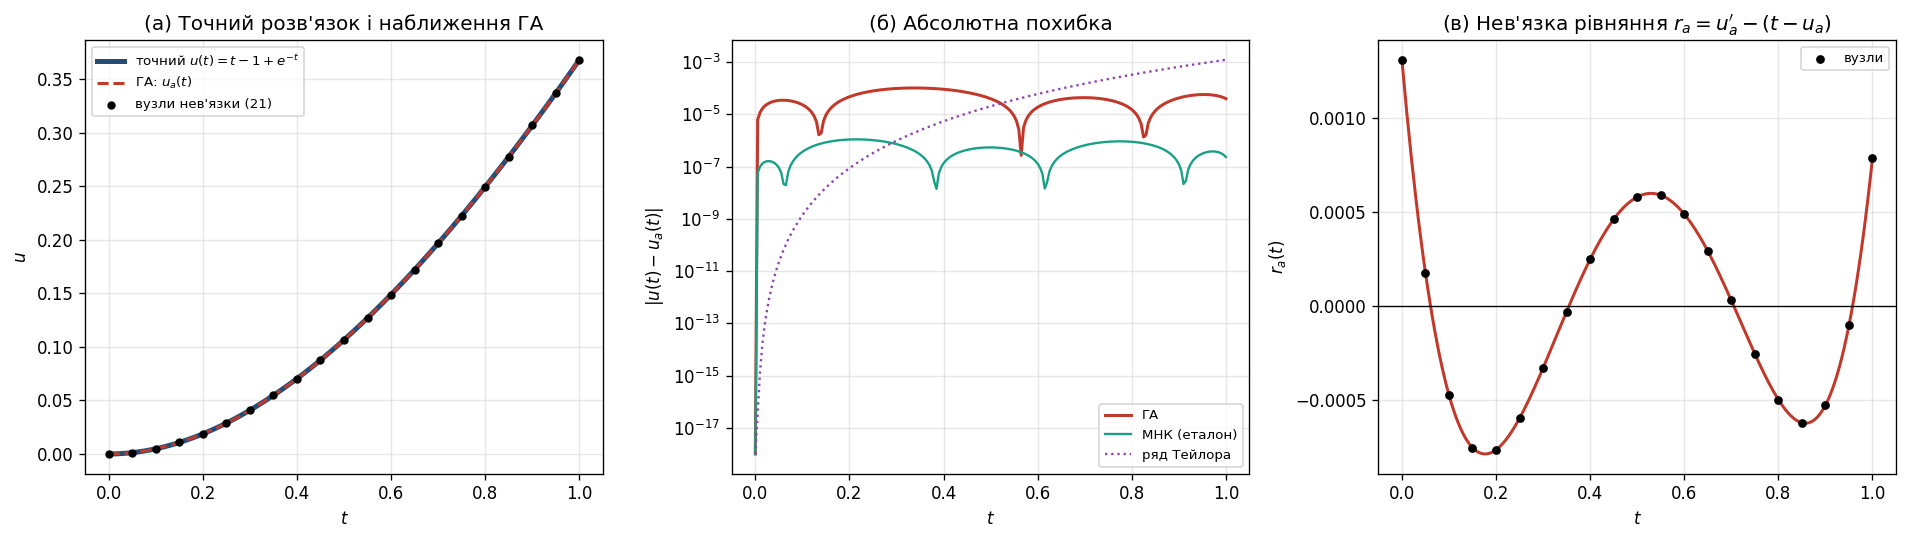

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

ax[0].plot(t_grid, u_ex, '-', lw=3, c='#1f4e79', label=r'точний $u(t)=t-1+e^{-t}$')
ax[0].plot(t_grid, u_ga, '--', lw=1.8, c='#c0392b', label=r'ГА: $u_a(t)$')
ax[0].scatter(t_nodes, u_exact(t_nodes), s=16, c='black', zorder=5,
              label='вузли нев\'язки (21)')
ax[0].set_xlabel('$t$'); ax[0].set_ylabel('$u$')
ax[0].set_title('(а) Точний розв\'язок і наближення ГА')
ax[0].legend(fontsize=8)

ax[1].semilogy(t_grid, err_ga + 1e-18, lw=1.8, c='#c0392b', label='ГА')
ax[1].semilogy(t_grid, np.abs(u_ex - u_ls) + 1e-18, lw=1.4, c='#16a085',
               label='МНК (еталон)')
ax[1].semilogy(t_grid, np.abs(u_ex - u_ta) + 1e-18, lw=1.4, c='#8e44ad',
               ls=':', label='ряд Тейлора')
ax[1].set_xlabel('$t$'); ax[1].set_ylabel(r'$|u(t)-u_a(t)|$')
ax[1].set_title('(б) Абсолютна похибка')
ax[1].legend(fontsize=8)

r_dense = np.column_stack([k * t_grid**(k-1) + t_grid**k for k in range(1, 6)]) @ a_ga - t_grid
ax[2].plot(t_grid, r_dense, lw=1.8, c='#c0392b')
ax[2].scatter(t_nodes, r_ga, s=18, c='black', zorder=5, label='вузли')
ax[2].axhline(0, c='black', lw=0.8)
ax[2].set_xlabel('$t$'); ax[2].set_ylabel(r'$r_a(t)$')
ax[2].set_title('(в) Нев\'язка рівняння $r_a = u_a\' - (t - u_a)$')
ax[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

### 3.6. Висновки (задача 3)

Важливі спостереження:

1. Оскільки $u_a(t) = u(0) + \sum a_k t^k$, умова $u_a(0) = u(0)$ виконується тотожно. Якби ми шукали значення $u$ у вузлах сітки, початкову умову довелося б включати у функцію пристосованості окремим штрафом, а це створює конфлікт двох цілей і ускладнює налаштування їхніх ваг.

2. **ГА тут поступається лінійному МНК на кілька порядків.** Нев'язка $r_{\mathbf{a}}(t) = \sum a_k(k t^{k-1}+t^k) - t$ лінійна за коефіцієнтами, тому $E(\mathbf{a})$ - опуклий квадратичний функціонал, мінімум якого знаходиться розв'язанням звичайної нормальної системи за частки секунди й з машинною точністю ($E \approx 5\cdot10^{-11}$). Генетичний алгоритм розв'язує цю ж задачу "наосліп" і витрачає $300 \times 6000 = 1.8$ млн обчислень фітнесу, щоб дійти до $E \approx 3\cdot10^{-7}$. **Перевага ГА** виявилася б, якби рівняння було **нелінійним** за невідомими коефіцієнтами (наприклад, $u' = u^2 + t$ з наближенням у вигляді раціональної функції), де лінійний МНК незастосовний.

3. **Коефіцієнти ГА помітно відрізняються від тейлорівських.** Можливо, причина в тому, що базисні функції $t^k$ на відрізку $[0,1]$ майже колінеарні: існує ціла велика кількість різних наборів $\mathbf{a}$, які дають майже однакову нев'язку. ГА знаходить одну з точок цієї долини. Доречніше порівнювати не коефіцієнти, а значення функції та нев'язку. Цікаво, що зрізаний ряд Тейлора, хоч його коефіцієнти "правильні", дає гіршу нев'язку ($E \approx 7.8\cdot10^{-6}$) і більшу максимальну похибку ($1.2\cdot10^{-3}$), ніж ГА: ряд Тейлора оптимізує поведінку біля нуля, а не рівномірну точність на всьому відрізку $[0,1]$.